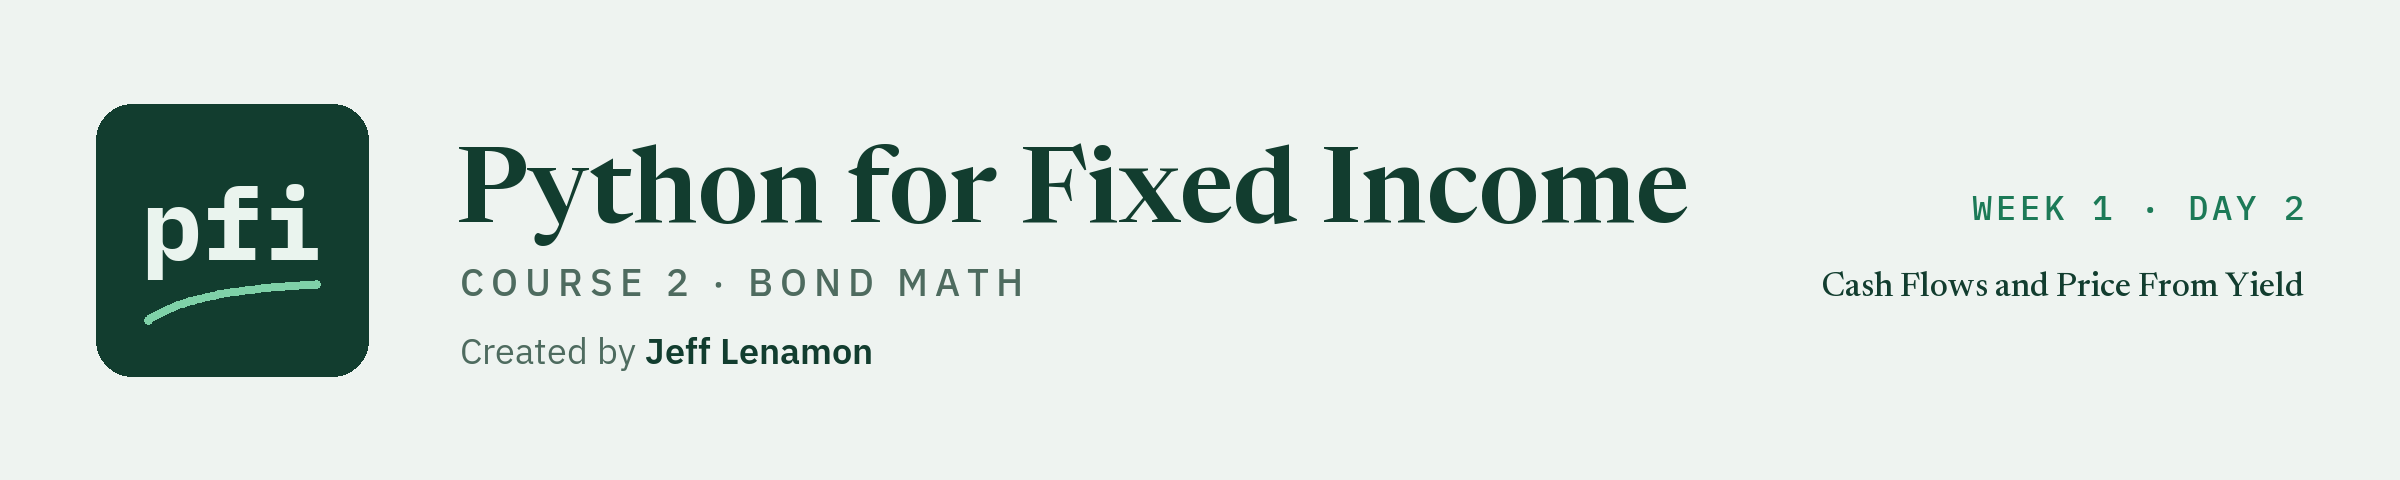

# Cash Flows and Price From Yield

Week 1, Day 2. A bond as a list of payments, its price on a coupon date as their discounted sum, and two more functions for your module, tested against Excel's PV and PRICE.

> This course is educational content created in a personal capacity. Nothing here is investment advice or a recommendation to buy or sell any security. All portfolio data is synthetic.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course02_bond_math/week1/day2/02_cash_flows_and_price_from_yield.ipynb)

### The Desk Lead's Note

> Notebook 01 valued each bond's 100 at maturity. That is not a price: Quorvane also pays ten coupons. List every payment each bond makes, price all four from their yields, and split each price into the 100 and the coupons. Put both steps in `bondmath`, docstring first, and prove them against Excel's PV and PRICE. Tell me why clean and dirty are the same number today. Read the change before you save it, and take it home.

The issuers are invented; every number describes the data.

**76.6118 is Quorvane's 100 today; now the coupons join it.**

### Start the Day

As in notebook 01, the setup makes a new work folder; this time it also holds the module, its tests, and notebook 01's commit.

In [1]:
import os
import sys

# start_day.py sets up each day. On your machine Python finds it in the repo's start_of_day folder;
# in Colab there is no repo, so the cell downloads it from the course's GitHub page.
github = 'https://raw.githubusercontent.com/lenamonj/python-fixed-income/main/course02_bond_math/'
if os.path.exists('../../start_of_day/start_day.py'):
    sys.path.insert(0, '../../start_of_day')
else:
    !wget -q {github}start_of_day/start_day.py
from start_day import start_day

# a new work folder: the Excel files, and the module, its tests, and its Git history
# as notebook 01 left them.
# To start the day again, restart the kernel and run all cells.
work = start_day(2)

Work folder pfi_course2_02_k4w7q2xr: 2 data files, the module as notebook 01 left it, 1 commit


### Imports and the House Colours

In [2]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

import bondmath

# the house greens and greys, as in Course 1's Visualization notebook
sns.set_theme(style='whitegrid', palette=['#2E7D5B', '#9AA5B1', '#1E4D3A', '#52606D'])

### The Module So Far

In [3]:
import subprocess
import sys

# python -m pytest -q with this notebook's own Python; -p no:cacheprovider: no cache folder
command = [sys.executable, '-m', 'pytest', '-q', '-p', 'no:cacheprovider']
# run it in the work folder and keep what it prints
result = subprocess.run(command, cwd=work, capture_output=True, text=True)
print(result.stdout + result.stderr)

...                                                                      [100%]
3 passed in 0.50s



**The module starts the day as notebook 01 left it: two functions, three tests.**

### The Four Bonds

Notebook 01's four bonds, each settling today, 30 September 2026, on a coupon date.

In [4]:
bonds = pd.DataFrame({
    'issuer': ['Quorvane Energy', 'Dunmarrow Rail', 'Pellwick Paper', 'Halvering Foods'],
    'ticker': ['QVNE', 'DNMR', 'PLWK', 'HLVF'],
    'coupon_pct': [5.25, 6.125, 4.75, 7.5],
    'years': [5, 7, 3, 10],
    'yield_pct': [5.4, 6.125, 4.6, 7.7],
})
bonds

,issuer,ticker,coupon_pct,years,yield_pct
0,Quorvane Energy,QVNE,5.250,5,5.400
1,Dunmarrow Rail,DNMR,6.125,7,6.125
2,Pellwick Paper,PLWK,4.750,3,4.600
3,Halvering Foods,HLVF,7.500,10,7.700


## 2.1 The Cash Flows of a Bullet Bond

![A timeline from 30 Sep 2026 to 30 Sep 2031 with a tick every half-year, payments 1 to 10. Nine short arrows of 2.625 and a tall tenth of 2.625 + 100 = 102.625. Below, the pieces: coupon each period = coupon_pct / frequency = 5.25 / 2 = 2.625, periods = frequency x years = 2 x 5 = 10, and the first payment is exactly one half-year away because the bond settles on a coupon date](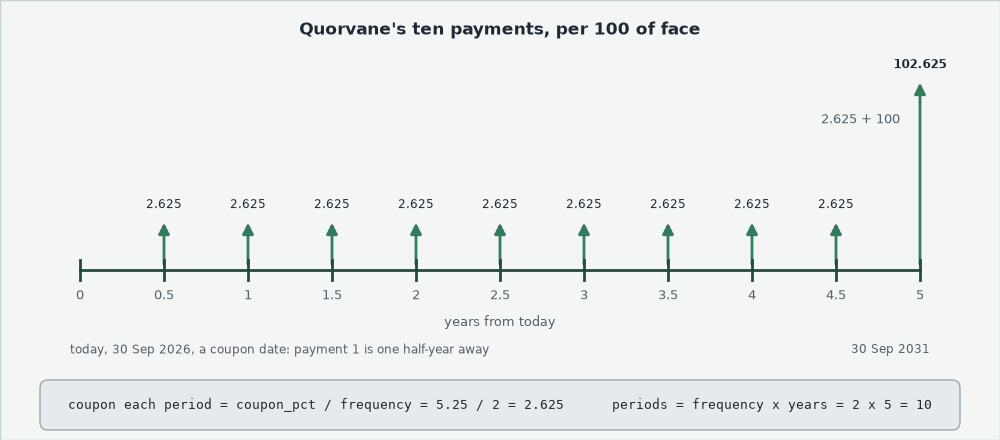)

A **bullet bond** pays a fixed coupon every period and repays all of its 100 on one day, at maturity.
Quorvane's 5.25 percent a year arrives as 2.625 every half-year, and the 100 comes with the last coupon.

### Quorvane's Ten Payments

Q. List every payment Quorvane makes, per 100 of face.

In [5]:
coupon = 5.25 / 2
rows = []
for k in range(1, 11):
    # payment k comes k half-years from today; the last one also repays the 100
    amount = coupon + 100 if k == 10 else coupon
    rows.append({'payment': k, 'time_years': k / 2, 'cash_flow': amount})
quorvane_flows = pd.DataFrame(rows)
quorvane_flows

,payment,time_years,cash_flow
0,1,0.5,2.625
1,2,1.0,2.625
2,3,1.5,2.625
3,4,2.0,2.625
4,5,2.5,2.625
5,6,3.0,2.625
6,7,3.5,2.625
7,8,4.0,2.625
8,9,4.5,2.625
9,10,5.0,102.625


The loop builds the flows Course 1's NumPy Part 2 built, and `x if test else y` is the one-line condition of Course 1's Introduction, Part 2.

### All the Cash

In [6]:
total_cash = quorvane_flows['cash_flow'].sum()
print(f'Total cash: {total_cash:.2f} per 100 of face, {total_cash - 100:.2f} of it coupons')

Total cash: 126.25 per 100 of face, 26.25 of it coupons


**Excel side by side.**

<table align="left">
<tr><th align="left">Job</th><th align="left">Python</th><th align="left">Excel</th><th align="left">Result</th></tr>
<tr><td align="left">The payments</td><td align="left"><code>quorvane_flows</code></td><td align="left"><code>=5.25/2</code> in B1, filled to B9; <code>=5.25/2+100</code> in B10</td><td align="left">2.625, then 102.625</td></tr>
<tr><td align="left">All the cash</td><td align="left"><code>total_cash</code></td><td align="left"><code>=SUM(B1:B10)</code></td><td align="left">126.25</td></tr>
</table>
<br clear="left">

### Four Bonds' Payments

Q. How many payments does each bond make, and how much cash in all?

In [7]:
bonds['payments'] = 2 * bonds['years']
bonds['coupon_each'] = bonds['coupon_pct'] / 2
bonds['total_cash'] = bonds['payments'] * bonds['coupon_each'] + 100
table = bonds[['ticker', 'payments', 'coupon_each', 'total_cash']]
table.style.format({'coupon_each': '{:.4f}', 'total_cash': '{:.2f}'}).hide(axis='index')

ticker,payments,coupon_each,total_cash
QVNE,10,2.6250,126.25
DNMR,14,3.0625,142.88
PLWK,6,2.3750,114.25
HLVF,20,3.7500,175.00


A quarterly bond would split the same year's coupon four ways: more payments, the same total.

### Cash to Maturity, Stacked

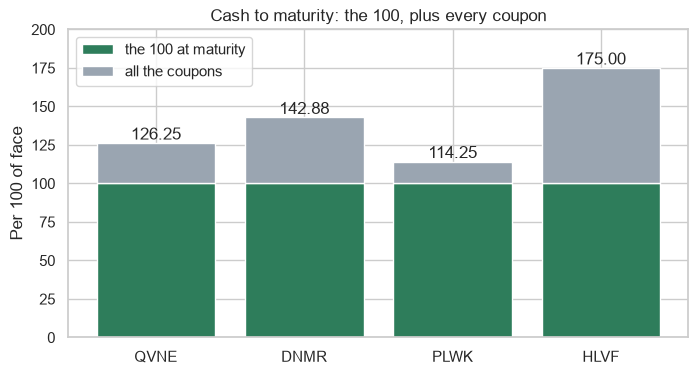

In [8]:
coupons_total = bonds['total_cash'] - 100
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(bonds['ticker'], 100, label='the 100 at maturity')
# bottom= stands each coupon bar on top of its 100
top = ax.bar(bonds['ticker'], coupons_total, bottom=100, label='all the coupons')
# labels= writes our own text above each bar
ax.bar_label(top, labels=[f'{cash:.2f}' for cash in bonds['total_cash']])
ax.set_ylim(0, 200)
ax.set_title('Cash to maturity: the 100, plus every coupon')
ax.set_ylabel('Per 100 of face')
ax.legend()
plt.show()

**Halvering pays 175.00 per 100 and Pellwick 114.25; what each is worth today is the next question.**

## 2.2 Price as the Sum of Discounted Cash Flows

**Predict 1**

Notebook 01 put Quorvane's 100 at maturity at 76.6118 today.
Add the ten coupons of 2.625, each discounted for its own wait.
What is the bond worth today, per 100?
Write down a number.

### Each Payment, Its Own Discount Factor

Payment k waits k half-years, so its discount factor is 1 / 1.027 to the power k, notebook 01's factor for its own wait.

In [9]:
period_yield = 5.4 / 100 / 2
# the whole column at once, as in NumPy Part 1
quorvane_flows['discount_factor'] = 1 / (1 + period_yield) ** quorvane_flows['payment']
quorvane_flows['present_value'] = quorvane_flows['cash_flow'] * quorvane_flows['discount_factor']
quorvane_flows.round(6)

,payment,time_years,cash_flow,discount_factor,present_value
0,1,0.5,2.625,0.973710,2.555988
1,2,1.0,2.625,0.948111,2.488791
2,3,1.5,2.625,0.923185,2.423360
3,4,2.0,2.625,0.898914,2.359650
4,5,2.5,2.625,0.875282,2.297614
5,6,3.0,2.625,0.852270,2.237209
6,7,3.5,2.625,0.829864,2.178393
7,8,4.0,2.625,0.808047,2.121123
8,9,4.5,2.625,0.786803,2.065358
9,10,5.0,102.625,0.766118,78.622841


### Add Them Up

In [10]:
price = quorvane_flows['present_value'].sum()
print(f"Quorvane's price at 5.40 percent: {price:.4f} per 100 of face")

Quorvane's price at 5.40 percent: 99.3503 per 100 of face


### Excel's Answer

In [11]:
tvm = pd.read_csv('bondmath_excel_reference_tvm.csv', index_col='case_id')
# Quorvane's row: its formula and what Excel returned
quorvane_row = tvm.loc['tvm_pv_bond_13']
print(quorvane_row['excel_formula'], 'returned', quorvane_row['excel_value'])

=-PV(5.4/100/2,2*5,5.25/2,100) returned 99.35032727691537


![Quorvane's ten payments in a row. Under each, its discount factor, 1 / 1.027 to the power k, from 0.973710 for payment 1 to 0.766118 for payment 10, and its present value, from 2.555988 to 78.622841. A brace gathers the ten present values: nine coupons worth 20.727486 and the last payment worth 78.622841 sum to 99.3503. The formula below: price = sum over k of CF_k / (1 + y / f) to the power k, with y / f = 5.40 / 100 / 2 = 0.027](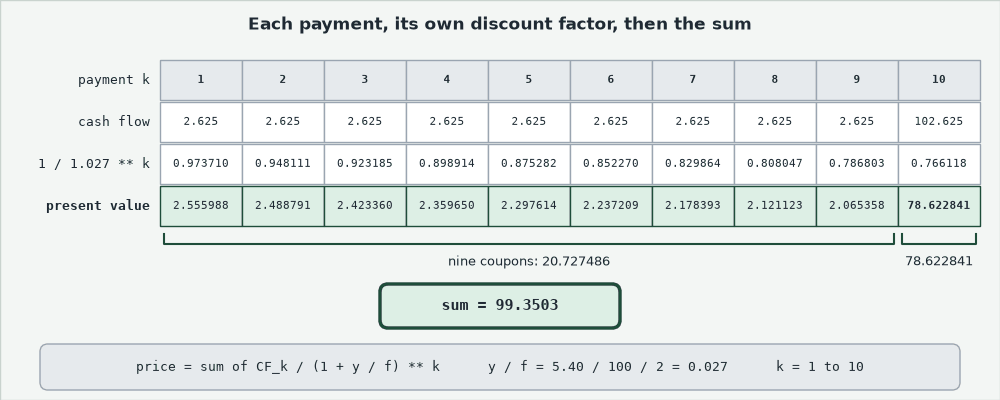)

### The 100 and the Coupons

Q. How much of 99.3503 is the 100, and how much the coupons?

In [12]:
# the last factor carries the 100; the rest of the price is coupons
redemption_pv = 100 * quorvane_flows['discount_factor'].iloc[-1]
coupons_pv = price - redemption_pv
print(f'The 100: {redemption_pv:.4f}. The coupons: {coupons_pv:.4f}')

The 100: 76.6118. The coupons: 22.7385


Notebook 01's 76.6118 is back, 77.1 percent of the price.

**Excel side by side.** Three routes to one price; `PRICE`, the fourth, comes in 2.5.

<table align="left">
<tr><th align="left">Job</th><th align="left">Python</th><th align="left">Excel</th><th align="left">Result</th></tr>
<tr><td align="left">Each payment discounted</td><td align="left"><code>present_value</code> column</td><td align="left">1 to 10 in A1:A10; <code>=B1/(1+5.4/100/2)^A1</code> in C1, filled to C10</td><td align="left">2.555988 to 78.622841</td></tr>
<tr><td align="left">Their sum</td><td align="left"><code>price</code></td><td align="left"><code>=SUM(C1:C10)</code></td><td align="left">99.350327</td></tr>
<tr><td align="left">One function over the payments</td><td align="left"></td><td align="left"><code>=NPV(5.4/100/2,B1:B10)</code></td><td align="left">99.350327</td></tr>
<tr><td align="left">One formula</td><td align="left"></td><td align="left"><code>=-PV(5.4/100/2,2*5,5.25/2,100)</code></td><td align="left">99.350327</td></tr>
<tr><td align="left">The 100 alone</td><td align="left"><code>redemption_pv</code></td><td align="left"><code>=-PV(5.4/100/2,2*5,0,100)</code></td><td align="left">76.611782</td></tr>
<tr><td align="left">The coupons alone</td><td align="left"><code>coupons_pv</code></td><td align="left"><code>=-PV(5.4/100/2,2*5,5.25/2,0)</code></td><td align="left">22.738545</td></tr>
</table>
<br clear="left">

`NPV` discounts its first value by one full period: right on a coupon date, where the first coupon is a half-year away.
`PV`'s third argument is the payment each period, the coupon; its fourth the amount at the end.

**99.3503: notebook 01's 76.6118 for the 100, plus 22.7385 for the coupons, and Excel agrees three ways.**

## 2.3 `cash_flows` and `price_from_yield` in Your Module

Both go in docstring first, as in notebook 01: units, convention, Excel.

### Append `cash_flows`

It returns a list of (time in years, amount) pairs, tuples as in Course 1's Introduction, Part 1, and the hint `-> list[tuple[float, float]]` says so.
It refuses a frequency other than 1, 2 or 4, and a term that is not a whole number of periods.
`1e-9` is 0.000000001, a tolerance, because decimals are not exact, as Course 1's Debugging notebook showed with `0.1 + 0.2`.

In [13]:
%%writefile -a bondmath.py


def cash_flows(coupon_pct: float, years: float, frequency: int = 2) -> list[tuple[float, float]]:
    """The cash flows of a bullet bond bought on a coupon date.

    Units: coupon_pct in percent of face a year, years in years. Each cash flow is per 100 of face.
    Convention: one coupon of coupon_pct / frequency every 1 / frequency years, and 100 back with
    the last coupon. Returns a list of (time in years, cash flow) pairs, earliest first.
    Raises ValueError unless years x frequency is a whole number of periods.
    """
    # stop on a frequency the course does not use
    if frequency not in (1, 2, 4):
        raise ValueError(f"frequency must be 1, 2, or 4, not {frequency}")
    # count the coupon periods and check they are whole
    periods = years * frequency
    if periods <= 0 or abs(periods - round(periods)) > 1e-9:
        raise ValueError(f"{years} years is not a whole number of periods at frequency {frequency}")
    periods = round(periods)
    # each coupon is the annual coupon split into equal parts
    coupon = coupon_pct / frequency
    flows = []
    for k in range(1, periods + 1):
        # the time of payment k, in years
        time_years = k / frequency
        # the last payment also returns the face of 100
        amount = coupon + 100 if k == periods else coupon
        flows.append((time_years, amount))
    return flows

Appending to bondmath.py


### Append `price_from_yield`

It calls `cash_flows`, then discounts each pair: `time_years * frequency` is the number of periods the payment waits.
The arguments run coupon, yield, years, as Excel's `PRICE` takes the coupon rate before the yield; Course 1's NumPy version took years second.

In [14]:
%%writefile -a bondmath.py


def price_from_yield(coupon_pct: float, yield_pct: float, years: float, frequency: int = 2) -> float:
    """Price of a bullet bond on a coupon date, from its yield.

    Units: coupon_pct and yield_pct in percent a year, years in years, price per 100 of face.
    Convention: each cash flow is discounted at yield_pct compounded `frequency` times a year.
    On a coupon date there is no accrued interest, so this is both the clean and the dirty price.
    Excel: =-PV(yield_pct/100/frequency, frequency*years, coupon_pct/frequency, 100)
    """
    # the yield for one period, as a decimal
    period_yield = yield_pct / 100 / frequency
    price = 0.0
    for time_years, amount in cash_flows(coupon_pct, years, frequency):
        # discount each cash flow by one factor per period until it is paid
        price += amount / (1 + period_yield) ** (time_years * frequency)
    return price

Appending to bondmath.py


![price_from_yield(5.25, 5.40, 5) passes the coupon, the years and the frequency to cash_flows(5.25, 5, 2), which checks that 2 x 5 = 10 periods is whole and returns ten pairs, (0.5, 2.625) to (5.0, 102.625). Back in price_from_yield each amount is divided by 1.027 to the power time x 2, and the ten results sum to 99.3503. A strip below sets the argument orders side by side: price_from_yield(coupon_pct, yield_pct, years, frequency), Excel PRICE(settlement, maturity, rate, yld, redemption, frequency, basis), and Course 1's NumPy price_from_yield(coupon, years, yield_pct)](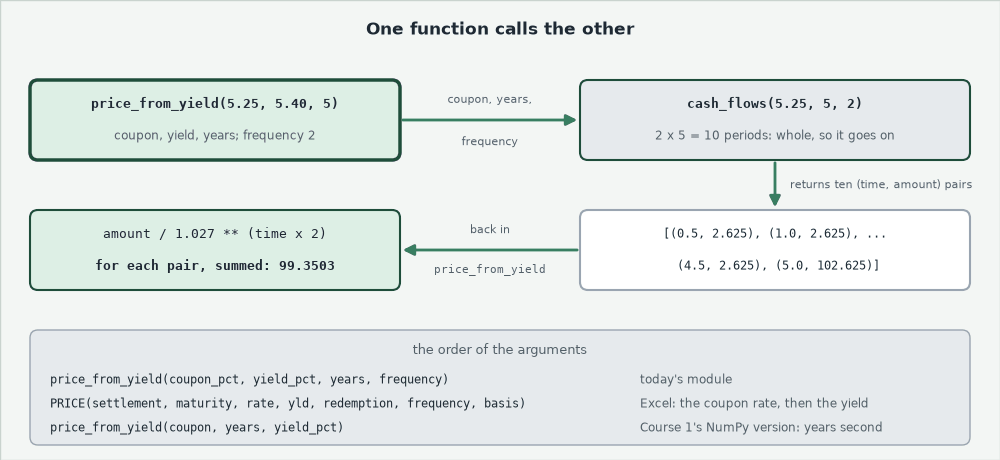)

The coupon rule lives in one place: `price_from_yield` never builds a payment itself.

### Reload and Compare

Q. Does the module give the same payments as the table of 2.1?

In [15]:
import importlib

# read the file again: the module in memory has neither function yet
importlib.reload(bondmath)
flows = bondmath.cash_flows(5.25, 5)
assert flows == list(zip(quorvane_flows['time_years'], quorvane_flows['cash_flow']))
print(len(flows), 'pairs, the same as the table. First and last:', flows[0], flows[-1])

10 pairs, the same as the table. First and last: (0.5, 2.625) (5.0, 102.625)


### A Part Period Is Refused

Q. What happens with 2.3 years, 4.6 half-years?

In [16]:
bondmath.cash_flows(5.25, 2.3)

ValueError: 2.3 years is not a whole number of periods at frequency 2

Excel's `=-PV(5.4/100/2,2*2.3,5.25/2,100)` takes 4.6 periods and returns 99.6796.
A bond pays whole coupons, so the module refuses rather than return a number that looks right.

### Four Bonds From the Module

Q. Price all four at their own yields, beside Excel's `-PV` rows.

In [17]:
bonds['price'] = [bondmath.price_from_yield(c, y, t)
                  for c, y, t in zip(bonds['coupon_pct'], bonds['yield_pct'], bonds['years'])]
cases = ['tvm_pv_bond_13', 'tvm_pv_bond_14', 'tvm_pv_bond_15', 'tvm_pv_bond_16']
bonds['excel'] = tvm.loc[cases, 'excel_value'].to_numpy()
table = bonds[['ticker', 'coupon_pct', 'yield_pct', 'price', 'excel']]
formats = {'coupon_pct': '{:.3f}', 'yield_pct': '{:.3f}', 'price': '{:.6f}', 'excel': '{:.6f}'}
table.style.format(formats).hide(axis='index')

ticker,coupon_pct,yield_pct,price,excel
QVNE,5.250,5.400,99.350327,99.350327
DNMR,6.125,6.125,100.000000,100.000000
PLWK,4.750,4.600,100.415887,100.415887
HLVF,7.500,7.700,98.622736,98.622736


Dunmarrow's coupon equals its yield, so it prices at 100, Course 1's par check.
A coupon above the yield prices above 100 (Pellwick), below it under 100; notebook 03 names the two.

### Price, Split in Two

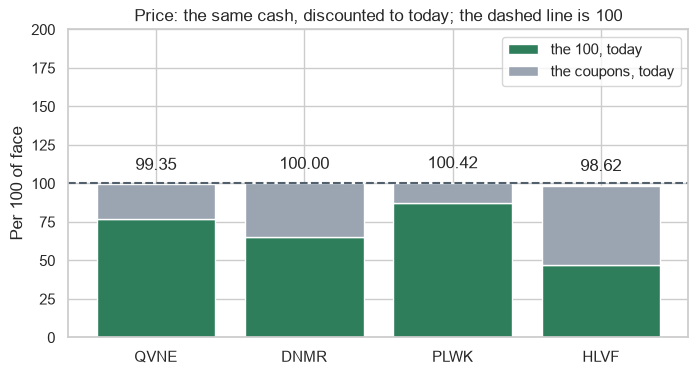

In [18]:
bonds['pv_of_100'] = [bondmath.present_value(100, y, t)
                      for y, t in zip(bonds['yield_pct'], bonds['years'])]
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(bonds['ticker'], bonds['pv_of_100'], label='the 100, today')
top = ax.bar(bonds['ticker'], bonds['price'] - bonds['pv_of_100'], bottom=bonds['pv_of_100'],
             label='the coupons, today')
# padding= lifts each label clear of the dashed line at 100
ax.bar_label(top, labels=[f'{p:.2f}' for p in bonds['price']], padding=8)
ax.axhline(100, color='#52606D', linestyle='--')
ax.set_ylim(0, 200)
ax.set_title('Price: the same cash, discounted to today; the dashed line is 100')
ax.set_ylabel('Per 100 of face')
ax.legend()
plt.show()

Same axis as the cash chart: Halvering's 175.00 falls to 98.62, and its 100 is now under half the price.
Pellwick's 100 is 87 percent of its price.

### Ask It

In [19]:
help(bondmath.price_from_yield)

Help on function price_from_yield in module bondmath:

price_from_yield(
    coupon_pct: float,
    yield_pct: float,
    years: float,
    frequency: int = 2
) -> float
    Price of a bullet bond on a coupon date, from its yield.

    Units: coupon_pct and yield_pct in percent a year, years in years, price per 100 of face.
    Convention: each cash flow is discounted at yield_pct compounded `frequency` times a year.
    On a coupon date there is no accrued interest, so this is both the clean and the dirty price.
    Excel: =-PV(yield_pct/100/frequency, frequency*years, coupon_pct/frequency, 100)



**Predict 2**

Price Quorvane at a yield of 0.

A) 100: a bond starts from its face
B) 126.25: nothing is discounted
C) An error: the function cannot discount at a zero yield

### A Yield of 0

In [20]:
print(bondmath.price_from_yield(5.25, 0, 5))

126.25


B: every discount factor is 1, so the price is 2.1's total cash.
Excel's `=-PV(0/100/2,2*5,5.25/2,100)` returns 126.25 too.

**Predict 3**

Double Quorvane's coupon to 10.50, same yield and years.

A) About 198.70: the price doubles
B) About 125.60: the extra 26.25 of coupons, in full
C) About 122.09: the extra coupons, discounted

### Twice the Coupon

In [21]:
doubled = bondmath.price_from_yield(10.5, 5.4, 5)
print(f'Coupon 10.50: {doubled:.4f}. Its coupons: {doubled - redemption_pv:.4f}')

Coupon 10.50: 122.0889. Its coupons: 45.4771


C: the 100 still discounts to 76.6118; only the coupons double, from 22.7385 to 45.4771.

### Price Against Coupon

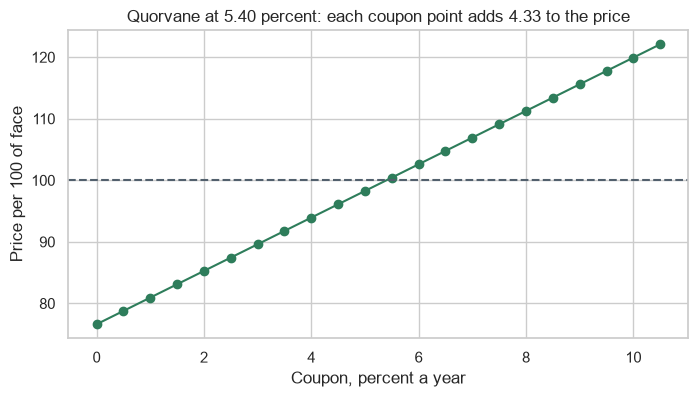

In [22]:
coupons = [k / 2 for k in range(22)]
prices = [bondmath.price_from_yield(c, 5.4, 5) for c in coupons]
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(coupons, prices, marker='o')
ax.axhline(100, color='#52606D', linestyle='--')
ax.set_title('Quorvane at 5.40 percent: each coupon point adds 4.33 to the price')
ax.set_xlabel('Coupon, percent a year')
ax.set_ylabel('Price per 100 of face')
plt.show()

A straight line from 76.6118 at no coupon to 122.0889 at 10.50, crossing 100 where the coupon equals the yield, 5.40.

**Two functions, one calling the other: the coupon rule lives in one place, and each coupon point is worth 4.33 per 100.**

## 2.4 Excel's Prices as Tests

### Two Tests for `cash_flows`

`REFERENCE` reads the dated answer key, `bondmath_excel_reference.csv`: one row per bond and settlement date.
The first test is a hand case: 6 percent for 5 years is ten coupons of 3.00, the last with the 100.
`pytest.approx` compares a pair item by item.
The second passes only if `cash_flows` refuses 2.3 years: `return` inside `except` ends the test there, and `assert False` fails it if no error came.

In [23]:
%%writefile -a test_bondmath.py


REFERENCE = read_rows("bondmath_excel_reference.csv")


def test_cash_flows_count_and_final_flow():
    flows = bondmath.cash_flows(6.0, 5, 2)
    # 5 years of half-year coupons is 10 cash flows
    assert len(flows) == 10
    # the first is a 3.00 coupon after half a year, the last is the coupon plus the face at 5 years
    assert flows[0] == pytest.approx((0.5, 3.0))
    assert flows[-1] == pytest.approx((5.0, 103.0))


def test_cash_flows_raises_on_part_periods():
    # 2.3 years is not a whole number of half years, so cash_flows must stop with a ValueError
    try:
        bondmath.cash_flows(6.0, 2.3, 2)
    except ValueError:
        return
    assert False, "cash_flows accepted 2.3 years at frequency 2"

Appending to test_bondmath.py


### A Test With a Filter

The price test reads every `PV_BOND` row, then keeps the dated rows that settle on a coupon date: `coupdaybs`, Excel's `COUPDAYBS`, the days since the last coupon, is `"0"`, in quotes because `read_rows` gives text.
`coupnum`, Excel's `COUPNUM`, the coupons left, over the frequency is the years.
`assert coupon_date_rows` stops a filter that found nothing: a test never passes by checking nothing.

In [24]:
%%writefile -a test_bondmath.py


def test_price_from_yield_matches_excel():
    # Excel's -PV with a coupon: a bond priced on a coupon date
    for row in tvm_rows("PV_BOND"):
        result = bondmath.price_from_yield(float(row["coupon_pct"]), float(row["rate_pct"]),
                                           float(row["years"]), int(row["frequency"]))
        assert result == pytest.approx(float(row["excel_value"]), abs=1e-6), row["case_id"]
    # Excel's PRICE on the rows that settle on a coupon date (no days accrued)
    coupon_date_rows = [row for row in REFERENCE if row["coupdaybs"] == "0"]
    assert coupon_date_rows, "no coupon-date rows in the reference file"
    for row in coupon_date_rows:
        frequency = int(row["frequency"])
        years = int(row["coupnum"]) / frequency
        result = bondmath.price_from_yield(float(row["coupon_pct"]), float(row["yield_pct"]), years, frequency)
        assert result == pytest.approx(float(row["price"]), abs=1e-6), row["case_id"]

Appending to test_bondmath.py


### Run pytest

In [25]:
import subprocess
import sys

# python -m pytest -q with this notebook's own Python; -p no:cacheprovider: no cache folder
command = [sys.executable, '-m', 'pytest', '-q', '-p', 'no:cacheprovider']
# run it in the work folder and keep what it prints
result = subprocess.run(command, cwd=work, capture_output=True, text=True)
print(result.stdout + result.stderr)

......                                                                   [100%]
6 passed in 0.50s



### How Many Excel Numbers

Q. Which rows did the price test read?

In [26]:
reference = pd.read_csv('bondmath_excel_reference.csv')
pv_bond_rows = tvm[tvm['function'] == 'PV_BOND']
coupon_date_rows = reference[reference['coupdaybs'] == 0]
print(len(pv_bond_rows), '-PV rows,', pv_bond_rows['years'].min(), 'to',
      pv_bond_rows['years'].max(), 'years. By frequency:',
      pv_bond_rows['frequency'].value_counts().sort_index().to_dict())
print(len(coupon_date_rows), 'PRICE rows on a coupon date. By basis:',
      coupon_date_rows['basis'].value_counts().sort_index().to_dict())

20 -PV rows, 1.0 to 30.0 years. By frequency: {1: 1, 2: 17, 4: 2}
17 PRICE rows on a coupon date. By basis: {0: 13, 1: 4}


**`6 passed`: `price_from_yield` matches Excel's -PV on 20 rows and PRICE on the 17 that settle on a coupon date; 2.5 says why only those.**

## 2.5 Clean Equals Dirty on a Coupon Date

**Accrued interest** is the part of the next coupon earned since the last one; the buyer pays it to the seller.
The **clean price** leaves it out: the quoted price, and what Excel's `PRICE` returns.
The **dirty price** is clean plus accrued: the cash that changes hands.

### The 17 Rows

In [27]:
print(f"Largest accrued on the 17 rows: {coupon_date_rows['accrued'].max():.6f} per 100")

Largest accrued on the 17 rows: 0.000000 per 100


On a coupon date nothing has accrued, so `price_from_yield` is both prices.

### A Bond Between Coupons

Q. The answer key's first row settles today too, but between its coupons. How far apart are its two prices?

In [28]:
row = reference.iloc[0]
dirty = row['price'] + row['accrued']
print(f"{row['case_id']}: last coupon {row['couppcd']},",
      f"{row['coupdaybs']} of {row['coupdays']} days ago")
print(f"Clean {row['price']:.6f} + accrued {row['accrued']:.6f} = dirty {dirty:.6f}")

99080CAE8: last coupon 2026-06-18, 102 of 180 days ago
Clean 106.726595 + accrued 1.983333 = dirty 108.709928


![Two rows, both settling on 30 Sep 2026. Quorvane sits on its coupon date, 0 days into a 180-day period: clean 99.3503 plus accrued 0 is dirty 99.3503. Bond 99080CAE8 sits 102 days into its 180-day period that began on 18 Jun 2026: accrued is its 3.50 half-year coupon x 102 / 180 = 1.983333, so clean 106.726595 plus accrued 1.983333 is dirty 108.709928](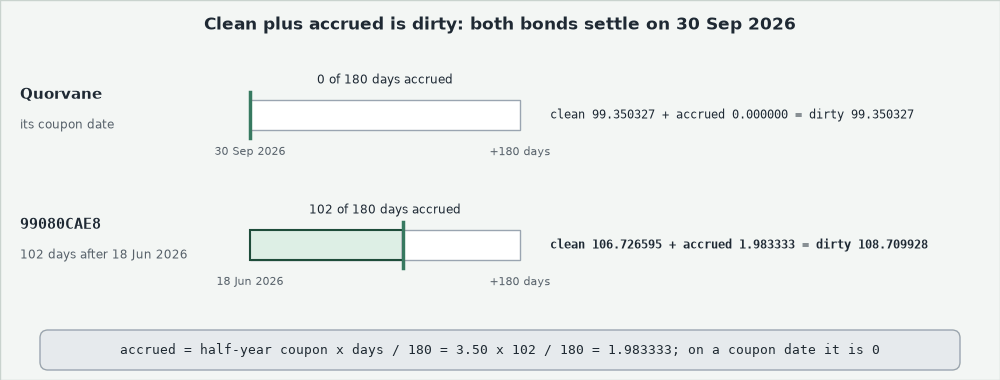)

Its accrued is the 3.50 half-year coupon times 102 / 180.
Notebook 07 counts the days; notebook 08 prices a bond between coupons.

**Excel side by side.**

<table align="left">
<tr><th align="left">Job</th><th align="left">Python</th><th align="left">Excel</th><th align="left">Result</th></tr>
<tr><td align="left">Clean price from the dates</td><td align="left"><code>bondmath.price_from_yield(5.25, 5.4, 5)</code></td><td align="left"><code>=PRICE(DATE(2026,9,30),DATE(2031,9,30),5.25/100,5.4/100,100,2,0)</code></td><td align="left">99.35032727691544</td></tr>
</table>
<br clear="left">

`PRICE`'s arguments, in order: settlement, maturity, rate (the coupon), yld, redemption, frequency, basis (0 is US 30/360), both rates as decimals.

**On a coupon date accrued is zero, so one number is both prices; between coupons they part, and notebook 08 prices that day.**

## 2.6 Read the Change, Then Commit

Read a change before you save it, whether it is yours, a colleague's, or an AI's.
`git diff` shows every line that changed since the last commit, here notebook 01's.

**Predict 4**

`%%writefile -a` has already saved both files to disk.
What will `git diff --stat` show?

A) Nothing: the files are saved
B) Lines added, and none removed
C) Every line of both files, removed and written again

### How Much Changed

In [29]:
# --stat: one line per file, with a count of lines added (+) and removed (-)
!git -C "{work}" diff --stat

 bondmath.py      | 45 +++++++++++++++++++++++++++++++++++++++++++++
 test_bondmath.py | 37 +++++++++++++++++++++++++++++++++++++
 2 files changed, 82 insertions(+)


B: saving a file is not committing it, and `-a` only adds lines.
No file is named that was not meant to change.

### Line by Line

In [30]:
!git -C "{work}" diff bondmath.py

diff --git a/bondmath.py b/bondmath.py
index 8590487..5a4e6a1 100644
--- a/bondmath.py
+++ b/bondmath.py
@@ -47,3 +47,48 @@ def present_value(amount: float, rate_pct: float, years: float, frequency: int =
     periods = frequency * years
     # discount the amount over every period
     return amount / (1 + period_rate) ** periods
+
+
+def cash_flows(coupon_pct: float, years: float, frequency: int = 2) -> list[tuple[float, float]]:
+    """The cash flows of a bullet bond bought on a coupon date.
+
+    Units: coupon_pct in percent of face a year, years in years. Each cash flow is per 100 of face.
+    Convention: one coupon of coupon_pct / frequency every 1 / frequency years, and 100 back with
+    the last coupon. Returns a list of (time in years, cash flow) pairs, earliest first.
+    Raises ValueError unless years x frequency is a whole number of periods.
+    """
+    # stop on a frequency the course does not use
+    if frequency not in (1, 2, 4):
+        raise ValueError(f"frequ

![The top of the real diff, labelled. a/bondmath.py is the file as last committed, b/bondmath.py the file now. The hunk header @@ -47,3 +47,48 @@ reads: the old file from line 47, 3 lines; the new file from line 47, 48 lines. Three context lines, unchanged, start with a space; the added lines start with + and are lit; no line starts with a minus sign, so nothing of notebook 01 was removed](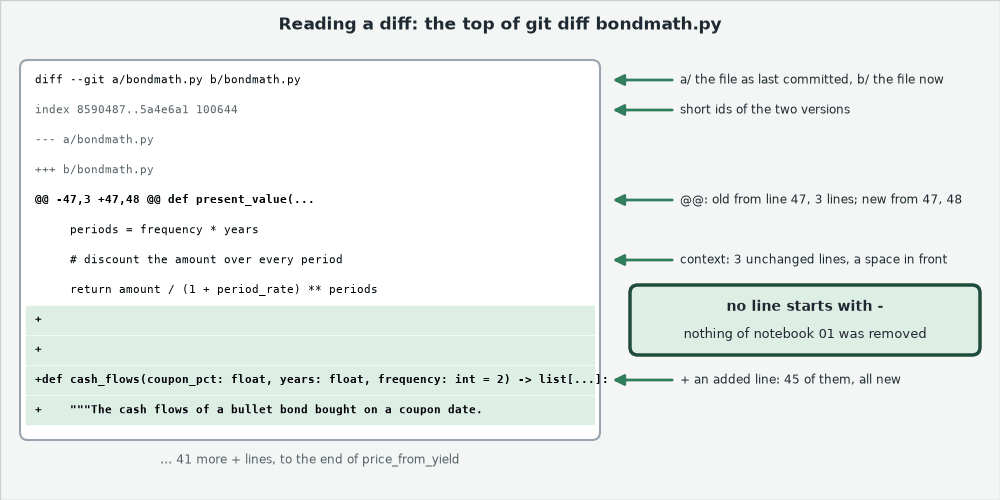)

Every new line starts with `+`; the three plain lines are context, unchanged, to show where the change sits.

### Commit and Read the History

`log --oneline` lists the commits, newest first, one line each.

In [31]:
!git -C "{work}" add bondmath.py test_bondmath.py
!git -C "{work}" commit -m "Notebook 02: cash_flows and price_from_yield"
!git -C "{work}" log --oneline

[main 408a678] Notebook 02: cash_flows and price_from_yield
 2 files changed, 82 insertions(+)
408a678 Notebook 02: cash_flows and price_from_yield
d029474 Notebook 01: future_value and present_value


**Added lines only, nothing of notebook 01 touched: a change worth committing.**

## Bring It Home

As in notebook 01, in a PowerShell terminal with the course's `.venv` active, with your own work folder.
The copy replaces your two files, so anything you added by hand, notebook 01's Exercise 4 included, goes: `git diff --stat` shows it as `-` lines, to read before you commit.

```powershell
# the work folder the setup cell printed
$work = "$env:TEMP\pfi_course2_02_k4w7q2xr"
Set-Location "$HOME\projects\my_bondmath"
Copy-Item "$work\bondmath.py", "$work\test_bondmath.py" .
python -m pytest -q
git diff --stat
git add bondmath.py test_bondmath.py
git commit -m "Notebook 02: cash_flows and price_from_yield"
git log --oneline
```

```
......                                                                   [100%]
6 passed in 0.50s
 bondmath.py      | 45 +++++++++++++++++++++++++++++++++++++++++++++
 test_bondmath.py | 37 +++++++++++++++++++++++++++++++++++++
 2 files changed, 82 insertions(+)
```

Git then reports the commit, "Notebook 02: cash_flows and price_from_yield", and `git log --oneline` lists it above notebook 01's.
In Colab, download the two `.py` files from the file browser on the left.
The work folder can stay: a restart makes a new one.

**`my_bondmath` holds four functions, six tests, and two commits.**

## You Can Now

By the end of this notebook, you can:

* List a bullet bond's payments: the coupon split by the frequency, and the 100 with the last.
* Price a bond on a coupon date as the sum of its discounted payments, and split the price into the 100 and the coupons.
* Get the same price in Excel four ways: a discounted column, `NPV`, `-PV` with the coupon, and `PRICE`.
* Write a function that returns a list of tuples, and one that calls another.
* Test against Excel with a filter that must find rows.
* Say why clean equals dirty on a coupon date.
* Read a change with `git diff` before you commit it.

## Exercises

**Every exercise has a worked answer** in the solutions notebook in this folder: the one with this notebook's name ending in `_solutions.ipynb`.

Give each exercise a real try first, then check your work against it.

The second desk's four bonds from notebook 01, now with their coupons, settle on the same coupon date.
Replace each `...` with your own code, then run the cell.
Run the next two cells first: the bonds and `check`.

In [32]:
exercise_bonds = pd.DataFrame({
    'issuer': ['Ostrevale Telecom', 'Tarnwick Utilities', 'Osmere Chemicals', 'Calderby Retail'],
    'ticker': ['OSTV', 'TRNW', 'OSMC', 'CLDB'],
    'coupon_pct': [5.625, 4.375, 5.0, 8.25],
    'years': [4, 2, 6, 8],
    'yield_pct': [5.8, 4.3, 5.35, 8.6],
})
exercise_bonds

,issuer,ticker,coupon_pct,years,yield_pct
0,Ostrevale Telecom,OSTV,5.625,4,5.80
1,Tarnwick Utilities,TRNW,4.375,2,4.30
2,Osmere Chemicals,OSMC,5.000,6,5.35
3,Calderby Retail,CLDB,8.250,8,8.60


In [33]:
# check() compares your answer with the expected one and prints the result
def check(label, answer, expected):
    if answer is ...:
        print(label + ': not attempted yet')
        return
    if answer is None:
        print(label + ': not yet. Nothing came back: does your function end with return?')
        return
    # isinstance(x, list) is True when x is a list, so a list answer is compared value by value
    if isinstance(expected, list):
        correct = list(answer) == expected  # the same values in the same order
    # getattr(answer, 'ndim', 0) reads answer's ndim, its number of dimensions, as in NumPy
    # Part 1, and gives 0 when answer has none: a single number or a piece of text
    elif getattr(answer, 'ndim', 0) > 0:
        correct = False  # a column or a table where one value is expected
    elif isinstance(expected, float):
        # abs() drops the sign, so this is the size of the gap between the two decimals
        correct = abs(answer - expected) < 0.000001  # decimals: within a tiny tolerance
    else:
        correct = answer == expected
    print(label + ': correct' if correct else label + ': not yet. You have ' + str(answer))

### Exercise 1

Q. Price each bond at its own yield with `bondmath.price_from_yield`. Store Osmere's price, unrounded, in **ex1_osmere** and a list of the tickers that price above 100 in **ex1_premium**.

In [34]:
ex1_osmere = ...
ex1_premium = ...
check('Exercise 1 Osmere', ex1_osmere, 98.2237648969068)
check('Exercise 1 above 100', ex1_premium, ['TRNW'])

Exercise 1 Osmere: not attempted yet
Exercise 1 above 100: not attempted yet


### Exercise 2

Q. List Calderby's payments with `bondmath.cash_flows`. Store their number in **ex2_payments**, the total cash per 100 in **ex2_total_cash**, and the share of its price that is the 100, in percent, in **ex2_redemption_share_pct**.

In [35]:
ex2_payments = ...
ex2_total_cash = ...
ex2_redemption_share_pct = ...
check('Exercise 2 payments', ex2_payments, 16)
check('Exercise 2 total cash', ex2_total_cash, 166.0)
check('Exercise 2 redemption share', ex2_redemption_share_pct, 52.023761197236674)

Exercise 2 payments: not attempted yet
Exercise 2 total cash: not attempted yet
Exercise 2 redemption share: not attempted yet


### Exercise 3

Q. The desk holds 5,000,000 dollars of face of Ostrevale, bought today, a coupon date. What does the position cost in dollars? Store it, unrounded, in **ex3_value_dollars**.

In [36]:
ex3_value_dollars = ...
check('Exercise 3 value in dollars', ex3_value_dollars, 4969158.881408045)

Exercise 3 value in dollars: not attempted yet


### Exercise 4

Q. Add `annual_coupon_income_dollars(par, coupon_pct)`, the coupon income in dollars that `par` dollars of face earn in a year, docstring first.
Add `test_annual_coupon_income_matches_cash_flows`: a hand case, then, for 1,000,000 dollars of face, one year of payments from `bondmath.cash_flows` on every `PV_BOND` row of 2 years or more, kept by a filtered comprehension.
Write each in its cell below and run it once, run pytest, reload the module, and store `bondmath.annual_coupon_income_dollars(5_000_000, 5.625)` in **ex4_value**.

In [37]:
%%writefile -a bondmath.py


# Exercise 4: write annual_coupon_income_dollars(par, coupon_pct) below this line

Appending to bondmath.py


In [38]:
%%writefile -a test_bondmath.py


# Exercise 4: write test_annual_coupon_income_matches_cash_flows() below this line

Appending to test_bondmath.py


In [39]:
import subprocess
import sys

# python -m pytest -q with this notebook's own Python; -p no:cacheprovider: no cache folder
command = [sys.executable, '-m', 'pytest', '-q', '-p', 'no:cacheprovider']
# run it in the work folder and keep what it prints
result = subprocess.run(command, cwd=work, capture_output=True, text=True)
print(result.stdout + result.stderr)

......                                                                   [100%]
6 passed in 0.50s



In [40]:
# reload the module, then call your function
ex4_value = ...
check('Exercise 4 coupon income', ex4_value, 281250.0)

Exercise 4 coupon income: not attempted yet


### Exercise 5: AI check

You gave an AI assistant `price_from_yield`'s docstring: the docstring is the prompt.
The function below came back; it runs, returns a reasonable number, and holds one convention error.

In [41]:
# written for this course in the style of an AI assistant's answer. It runs, and it holds one bug.
def assistant_price_from_yield(coupon_pct, yield_pct, years, frequency=2):
    """Price of a bullet bond on a coupon date, from its yield.

    Units: coupon_pct and yield_pct in percent a year, years in years, price per 100 of face.
    Convention: each cash flow is discounted at yield_pct compounded `frequency` times a year.
    """
    periods = round(years * frequency)
    period_yield = yield_pct / 100 / frequency
    price = 0.0
    for k in range(1, periods + 1):
        # each coupon, and the face of 100 with the last one
        amount = coupon_pct + 100 if k == periods else coupon_pct
        price += amount / (1 + period_yield) ** k
    return price

Q. Test it against every `PV_BOND` row before you trust it.

In [42]:
columns = zip(pv_bond_rows.index, pv_bond_rows['coupon_pct'], pv_bond_rows['rate_pct'],
              pv_bond_rows['years'], pv_bond_rows['frequency'], pv_bond_rows['excel_value'])
for case, coupon_pct, yield_pct, years, frequency, excel in columns:
    result = assistant_price_from_yield(coupon_pct, yield_pct, years, frequency)
    # rate_pct is the yield; Excel's -PV with the coupon is the price
    assert abs(result - excel) < 1e-6, f'{case}: {result:.6f} against {excel:.6f}'
print(f'All {len(pv_bond_rows)} PV_BOND rows match Excel')

AssertionError: tvm_pv_bond_01: 112.290325 against 98.634408

Q. Find the convention the code broke, fix it in its cell, and run both cells again until every row matches. Store `assistant_price_from_yield(5.25, 5.4, 5)` in **ex5_quorvane** and the rows checked in **ex5_rows**.

In [43]:
ex5_quorvane = ...
ex5_rows = ...
check('Exercise 5 Quorvane', ex5_quorvane, 99.35032727691542)
check('Exercise 5 rows checked', ex5_rows, 20)

Exercise 5 Quorvane: not attempted yet
Exercise 5 rows checked: not attempted yet


## Congratulations!

The note is answered:

<table align="left">
<tr><th align="left">The note asked</th><th align="left">Answer</th></tr>
<tr><td align="left">Every payment</td><td align="left">10, 14, 6 and 20 payments; 114.25 to 175.00 per 100 in all</td></tr>
<tr><td align="left">Four prices</td><td align="left">99.3503, 100.0000, 100.4159, 98.6227</td></tr>
<tr><td align="left">The split</td><td align="left">Quorvane: 76.6118 for the 100, 22.7385 for the coupons</td></tr>
<tr><td align="left">In the module, docstring first</td><td align="left"><code>cash_flows</code>, <code>price_from_yield</code></td></tr>
<tr><td align="left">Against Excel</td><td align="left"><code>6 passed</code>, 37 rows of -PV and PRICE</td></tr>
<tr><td align="left">Clean and dirty</td><td align="left">the same today: accrued is 0</td></tr>
<tr><td align="left">Read, saved, taken home</td><td align="left">the diff read, the second commit, <code>my_bondmath</code></td></tr>
</table>
<br clear="left">

Be proud: your module now prices a bond the way Excel's `PRICE` does, and you read every line before you saved it.
Next, The Price-Yield Relationship: why a bond prices above or below par, and how far it moves when its yield moves.